# 02 · Nettoyage et transformation des données

**Objectif :** transformer le fichier brut en un dataset **complet** (aucune valeur manquante) et **entièrement numérique**, prêt pour la modélisation.

**Principes suivis :**

- on ne modifie jamais les données brutes : on travaille sur une **copie** ;
- chaque choix (suppression, imputation, encodage) est **justifié par écrit**, en s'appuyant sur les constats de l'EDA (notebook `01_decouverte_dataset`) ;
- le résultat est **vérifié** puis **exporté** pour le notebook de modélisation.

## Sommaire

0. Rappel des constats de l'EDA
1. Chargement
2. Suppression des colonnes sans valeur prédictive
3. Extraction du titre depuis `Name`
4. Traitement des valeurs manquantes
5. Valeurs particulières (billets à 0 £, valeurs extrêmes)
6. Encodage des variables catégorielles
7. Vérifications finales
8. Export
9. Récapitulatif des choix

## 0. Rappel des constats de l'EDA

| Colonne | Problème observé | Traitement retenu |
|---|---|---|
| `PassengerId`, `Ticket` | Pas d'information prédictive directe | Suppression |
| `Name` | Information cachée (titre) | Extraction du titre, puis suppression |
| `Embarked` | 2 manquants | Imputation par la valeur la plus fréquente |
| `Cabin` | 77 % de manquants, absence informative | Création de `HasCabin`, puis suppression |
| `Age` | 20 % de manquants, liés à la classe | Imputation par la médiane du titre |
| `Fare` | Très asymétrique, 15 valeurs à 0 | Conservation |
| `Sex`, `Embarked`, `Title` | Texte | Encodage |

## 1. Chargement

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../Dataset/dataset-titanic-6afac2fa9ddd8043393546.csv")
OUTPUT_PATH = Path("../Dataset/titanic_clean.csv")

In [2]:
df_brut = pd.read_csv(DATA_PATH)   # données d'origine : on n'y touche plus
df = df_brut.copy()                # copie de travail

print(f"Dataset brut : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print("\nValeurs manquantes :")
print(df.isna().sum()[df.isna().sum() > 0])

Dataset brut : 891 lignes × 12 colonnes

Valeurs manquantes :
Age         177
Cabin       687
Embarked      2
dtype: int64


## 2. Suppression des colonnes sans valeur prédictive

| Colonne | Justification |
|---|---|
| `PassengerId` | Simple numéro de ligne attribué dans le fichier : il ne décrit pas le passager. Le garder pourrait faire apprendre au modèle un motif sans aucun sens. |
| `Ticket` | 681 valeurs différentes pour 891 passagers, au format hétérogène (`PC 17599`, `A/5 21171`, `LINE`…). Presque chaque valeur est unique : le modèle ne peut pas en tirer une règle générale. |

In [3]:
df = df.drop(columns=["PassengerId", "Ticket"])
df.columns.tolist()

['Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Fare',
 'Cabin',
 'Embarked']

## 3. Extraction du titre depuis `Name`

Le nom suit toujours le format `Nom, Titre. Prénoms`. Le titre est le texte entre la virgule et le point.

Cette étape est faite **avant** le traitement des valeurs manquantes, car le titre sert à imputer l'âge (voir la section 4.3).

In [4]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

**Regroupement des titres.** 17 titres différents, dont beaucoup ne concernent qu'1 ou 2 personnes. Un modèle ne peut rien apprendre d'une catégorie aussi rare. On regroupe donc :

- `Mlle` → `Miss` et `Mme` → `Mrs` : ce sont les équivalents français ;
- `Ms` → `Miss` : une seule passagère, de 28 ans, sans conjoint à bord ;
- tous les autres (Dr, Rev, Col, Major, Capt, Sir, Lady, the Countess, Don, Jonkheer) → `Rare`. Il s'agit de titres professionnels, militaires ou nobles, portés par des adultes plutôt âgés.

In [5]:
correspondances = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
df["Title"] = df["Title"].replace(correspondances)

titres_principaux = ["Mr", "Miss", "Mrs", "Master"]
df["Title"] = df["Title"].where(df["Title"].isin(titres_principaux), "Rare")

df["Title"].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

In [6]:
# Le nom complet n'est plus utile : son information a été extraite
df = df.drop(columns="Name")

## 4. Traitement des valeurs manquantes

### 4.1 `Embarked` : 2 valeurs manquantes → `S`

**Justification :**

- seulement 2 lignes sur 891 (0,2 %) : l'impact sur l'analyse est négligeable ;
- Southampton (`S`) est de loin le port le plus fréquent (72 % des passagers) : c'est la valeur la plus probable ;
- les deux passagères (Mme Stone et sa domestique Mlle Icard) ont, d'après les sources historiques (*Encyclopedia Titanica*), effectivement embarqué à **Southampton**.

On aurait aussi pu supprimer ces 2 lignes, mais elles contiennent des informations complètes sur les autres colonnes : les imputer est préférable.

In [7]:
mode_embarked = df["Embarked"].mode()[0]
print("Valeur la plus fréquente :", mode_embarked)

df["Embarked"] = df["Embarked"].fillna(mode_embarked)
print("Manquants restants :", df["Embarked"].isna().sum())

Valeur la plus fréquente : S
Manquants restants : 0


### 4.2 `Cabin` : 77 % de valeurs manquantes → création de `HasCabin`

**Pourquoi ne pas imputer ?** Avec 687 valeurs manquantes sur 891, toute imputation reviendrait à **inventer** plus des trois quarts de la colonne.

**Pourquoi ne pas simplement supprimer ?** L'EDA a montré que l'absence de cabine **n'est pas aléatoire** : elle touche 98 % des passagers de 3e classe contre 19 % en 1re, et les passagers avec une cabine connue ont survécu à 67 % contre 30 %. Cette absence est donc une information.

**Choix retenu :** on conserve uniquement l'information « cabine connue ou non » dans une nouvelle colonne `HasCabin` (1 = connue, 0 = inconnue), puis on supprime `Cabin`.

In [8]:
df["HasCabin"] = df["Cabin"].notna().astype(int)
df = df.drop(columns="Cabin")

df.groupby("HasCabin")["Survived"].agg(taux_survie="mean", effectif="count").round(2)

,taux_survie,effectif
HasCabin,,
0,0.30,687
1,0.67,204


### 4.3 `Age` : 20 % de valeurs manquantes → médiane par titre

**Options envisagées :**

| Option | Problème |
|---|---|
| Supprimer les 177 lignes | Perte de 20 % des passagers, surtout en 3e classe : l'échantillon deviendrait biaisé |
| Médiane globale (28 ans) | Donnerait 28 ans aux 4 jeunes garçons (`Master`) sans âge, dont l'âge médian est 3,5 ans |
| **Médiane par titre** | **Retenue** |

**Justification :** l'EDA a montré que le titre donne une très bonne indication de l'âge (Master : 3,5 ans ; Miss : 21 ans ; Mr : 30 ans ; Mrs : 35 ans). La médiane est préférée à la moyenne car elle est moins sensible aux valeurs extrêmes.

In [9]:
mediane_par_titre = df.groupby("Title")["Age"].median()
print("Âge médian par titre (calculé sur les âges connus) :")
print(mediane_par_titre)
print("\nÂges manquants par titre :")
print(df.loc[df["Age"].isna(), "Title"].value_counts())

Âge médian par titre (calculé sur les âges connus) :
Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64

Âges manquants par titre :
Title
Mr        119
Miss       36
Mrs        17
Master      4
Rare        1
Name: count, dtype: int64


In [10]:
age_avant = df["Age"].copy()   # gardé pour comparer avant / après

df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
print("Manquants restants :", df["Age"].isna().sum())

Manquants restants : 0


**Vérification : l'imputation a-t-elle déformé la distribution de l'âge ?**

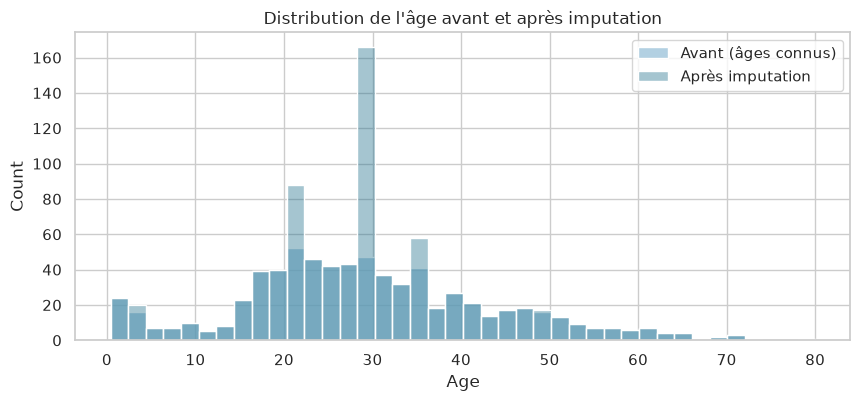

,avant,après
count,714.00,891.00
mean,29.70,29.39
std,14.53,13.27
min,0.42,0.42
25%,20.12,21.00
50%,28.00,30.00
75%,38.00,35.00
max,80.00,80.00


In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(age_avant.dropna(), bins=40, color="#98C1D9", label="Avant (âges connus)", ax=ax)
sns.histplot(df["Age"], bins=40, color="#1F6F8B", alpha=0.4, label="Après imputation", ax=ax)
ax.set_title("Distribution de l'âge avant et après imputation")
ax.legend()
plt.show()

pd.DataFrame({"avant": age_avant.describe(), "après": df["Age"].describe()}).round(2)

**Lecture :**

- la **moyenne** bouge très peu (29,7 → 29,4 ans) ;
- la **médiane** passe de 28 à 30 ans : c'est logique, car 119 des 177 âges manquants concernent des `Mr`, imputés à 30 ans ;
- on voit des **pics** aux valeurs imputées (21, 30 et 35 ans), et l'écart-type diminue (14,5 → 13,3). C'est la limite de toute imputation par une valeur unique, qui « resserre » la distribution.

Ces effets restent modérés et sont le prix à payer pour garder les 177 passagers. Ils sont aussi moins marqués qu'avec une médiane globale unique.

> **Limite assumée (fuite de données) :** en toute rigueur, les médianes devraient être calculées uniquement sur le jeu d'entraînement, après la séparation train/test, pour que le jeu de test n'influence pas la préparation. Ici, l'imputation est faite sur l'ensemble du dataset par souci de lisibilité. L'impact est faible : ce sont des médianes par titre, peu sensibles à l'ajout ou au retrait de 20 % des lignes.

## 5. Valeurs particulières

### 5.1 Les billets à 0 £ : conservés

L'EDA a montré que ces 15 passagers (tous des hommes, embarqués à Southampton) forment un **groupe réel** : très probablement des membres du personnel voyageant gratuitement. Ce ne sont ni des erreurs ni des prix manquants. Les remplacer par une médiane effacerait cette réalité.

### 5.2 Les valeurs extrêmes de `Fare`, `Age`, `SibSp`, `Parch` : conservées

Toutes ont été jugées **plausibles** pendant l'EDA (billets de luxe de 1re classe, passagers âgés, familles nombreuses). Les supprimer reviendrait à perdre de l'information réelle. Si besoin, une transformation (par exemple un logarithme sur `Fare`) pourra être testée à l'étape de modélisation.

In [12]:
print("Billets à 0 £ conservés :", (df["Fare"] == 0).sum())
print("Prix maximum conservé    :", df["Fare"].max())

Billets à 0 £ conservés : 15
Prix maximum conservé    : 512.3292


## 6. Encodage des variables catégorielles

Les modèles de scikit-learn n'acceptent que des nombres. Chaque variable texte est encodée selon sa nature :

| Variable | Nature | Encodage | Justification |
|---|---|---|---|
| `Sex` | 2 modalités | **Binaire** (male = 0, female = 1) | Une seule colonne suffit |
| `Embarked` | 3 ports, sans ordre | **One-Hot** | Un encodage 0/1/2 ferait croire au modèle que C < Q < S |
| `Title` | 5 titres, sans ordre | **One-Hot** | Même raison |
| `Pclass` | Déjà numérique (1, 2, 3) | **Conservée telle quelle** | L'ordre a un sens : 1re > 2e > 3e classe |

**`drop_first=True`** : avec le One-Hot, la dernière colonne se déduit des autres (si ni Q ni S, alors C). On supprime donc une colonne par variable pour éviter cette redondance, qui gêne les modèles linéaires comme la régression logistique. La modalité supprimée devient la **référence**.

In [13]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

df = pd.get_dummies(df, columns=["Embarked", "Title"], drop_first=True, dtype=int)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,22.0,1,0,7.2500,0,0,1,0,1,0,0
1,1,1,1,38.0,1,0,71.2833,1,0,0,0,0,1,0
2,1,3,1,26.0,0,0,7.9250,0,0,1,1,0,0,0
3,1,1,1,35.0,1,0,53.1000,1,0,1,0,0,1,0
4,0,3,0,35.0,0,0,8.0500,0,0,1,0,1,0,0


**Lecture des nouvelles colonnes :**

- `Embarked_Q` et `Embarked_S` : la référence est **Cherbourg** (`C`), qui correspond à 0 sur les deux colonnes ;
- `Title_Miss`, `Title_Mr`, `Title_Mrs`, `Title_Rare` : la référence est **Master**.

## 7. Vérifications finales

On vérifie automatiquement les critères du brief : si une condition n'est pas remplie, la cellule s'arrête avec une erreur.

In [14]:
assert df.isna().sum().sum() == 0, "Il reste des valeurs manquantes"
assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes), "Il reste des colonnes non numériques"
assert len(df) == len(df_brut), "Des lignes ont été perdues"

print("✅ Aucune valeur manquante")
print("✅ Toutes les colonnes sont numériques")
print(f"✅ Aucune ligne perdue ({len(df)} passagers)")
print(f"\nDataset final : {df.shape[0]} lignes × {df.shape[1]} colonnes")

✅ Aucune valeur manquante
✅ Toutes les colonnes sont numériques
✅ Aucune ligne perdue (891 passagers)

Dataset final : 891 lignes × 14 colonnes


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    int64  
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   HasCabin    891 non-null    int64  
 8   Embarked_Q  891 non-null    int64  
 9   Embarked_S  891 non-null    int64  
 10  Title_Miss  891 non-null    int64  
 11  Title_Mr    891 non-null    int64  
 12  Title_Mrs   891 non-null    int64  
 13  Title_Rare  891 non-null    int64  
dtypes: float64(2), int64(12)
memory usage: 97.6 KB


In [16]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Sex,891.0,0.35,0.48,0.00,0.00,0.00,1.0,1.00
Age,891.0,29.39,13.27,0.42,21.00,30.00,35.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33
HasCabin,891.0,0.23,0.42,0.00,0.00,0.00,0.0,1.00
Embarked_Q,891.0,0.09,0.28,0.00,0.00,0.00,0.0,1.00
Embarked_S,891.0,0.73,0.45,0.00,0.00,1.00,1.0,1.00


## 8. Export

In [17]:
df.to_csv(OUTPUT_PATH, index=False)
print(f"Dataset nettoyé enregistré : {OUTPUT_PATH}")

Dataset nettoyé enregistré : ../Dataset/titanic_clean.csv


## 9. Récapitulatif des choix

| Étape | Colonne | Décision | Justification |
|---|---|---|---|
| Suppression | `PassengerId` | Supprimée | Numéro de ligne, ne décrit pas le passager |
| Suppression | `Ticket` | Supprimée | Valeurs quasi uniques et hétérogènes |
| Extraction | `Name` → `Title` | Titre extrait et regroupé en 5 catégories, `Name` supprimée | Le titre indique le sexe, l'âge et le statut ; les titres rares sont regroupés |
| Manquants | `Embarked` (2) | Remplacés par `S` | Valeur la plus fréquente, confirmée par les sources historiques |
| Manquants | `Cabin` (687) | Remplacée par `HasCabin` (0/1) | Trop vide pour être imputée, mais l'absence est informative |
| Manquants | `Age` (177) | Médiane par titre | Le titre prédit bien l'âge, mieux qu'une médiane globale |
| Valeurs particulières | `Fare` = 0, valeurs extrêmes | Conservées | Valeurs réelles, pas des erreurs |
| Encodage | `Sex` | Binaire (0/1) | 2 modalités |
| Encodage | `Embarked`, `Title` | One-Hot (`drop_first`) | Catégories sans ordre |
| Encodage | `Pclass` | Inchangée | Ordre naturel |

**Résultat :** 891 passagers, 14 colonnes, aucune valeur manquante, uniquement des variables numériques.